In [1]:
import json, shutil, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
TASK = Path.cwd().parent
INPUT, OUTPUT = TASK / 'input', TASK / 'output'

In [3]:
config = json.loads((INPUT / 'config.json').read_text())
SEED = config['seed']
rng = np.random.default_rng(SEED)

In [4]:
for cell in json.loads((INPUT / 'helpers.ipynb').read_text())['cells']:
    exec(''.join(cell['source']), globals())
carry(INPUT, OUTPUT)

In [5]:
summary = pd.read_csv(INPUT / 'summary.csv')
trials = pd.read_csv(INPUT / 'trial_metrics.csv')
gains = pd.read_csv(INPUT / 'paired_gains.csv')
queries = pd.read_csv(INPUT / 'queries.csv')
index = pd.read_csv(INPUT / 'prediction_index.csv')
truth = np.load(INPUT / 'truth.npz')['ancestry']
with np.load(INPUT / 'predictions.npz') as data:
    pred = {key: data[key] for key in data.files}

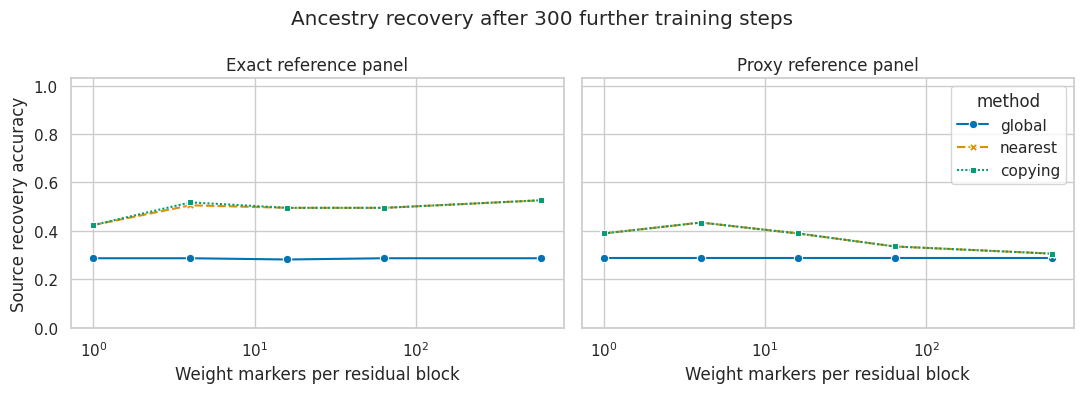

In [6]:
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
method_order = ['global', 'nearest', 'copying']
palette = dict(zip(method_order, sns.color_palette('colorblind', 3)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, panel in zip(axes, ['exact', 'proxy']):
    subset = summary.query("panel == @panel and kind == 'long' and variant == 'aligned' and steps == 300")
    sns.lineplot(data=subset, x='markers', y='block_accuracy', hue='method', style='method',
        hue_order=method_order, style_order=method_order, palette=palette, markers=True, dashes=True, ax=ax)
    ax.set(xscale='log', ylim=(0, 1.03), title=f'{panel.capitalize()} reference panel',
           xlabel='Weight markers per residual block', ylabel='Source recovery accuracy')
axes[0].get_legend().remove()
fig.suptitle('Ancestry recovery after 300 further training steps')
fig.tight_layout()
fig.savefig(OUTPUT / 'marker_recovery.png', dpi=180, bbox_inches='tight')
plt.show()

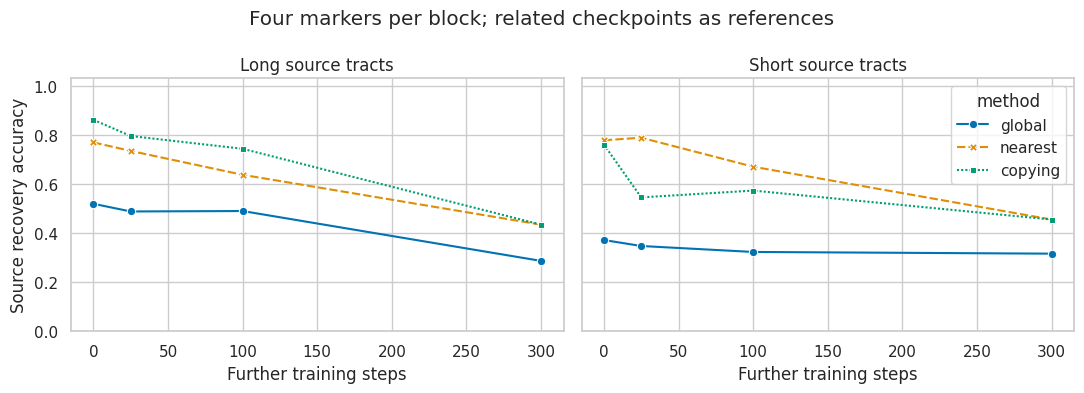

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, kind in zip(axes, ['long', 'short']):
    subset = summary.query("panel == 'proxy' and kind == @kind and variant == 'aligned' and markers == 4")
    sns.lineplot(data=subset, x='steps', y='block_accuracy', hue='method', style='method',
        hue_order=method_order, style_order=method_order, palette=palette, markers=True, dashes=True, ax=ax)
    ax.set(ylim=(0, 1.03), title=f'{kind.capitalize()} source tracts',
           xlabel='Further training steps', ylabel='Source recovery accuracy')
axes[0].get_legend().remove()
fig.suptitle('Four markers per block; related checkpoints as references')
fig.tight_layout()
fig.savefig(OUTPUT / 'training_recovery.png', dpi=180, bbox_inches='tight')
plt.show()

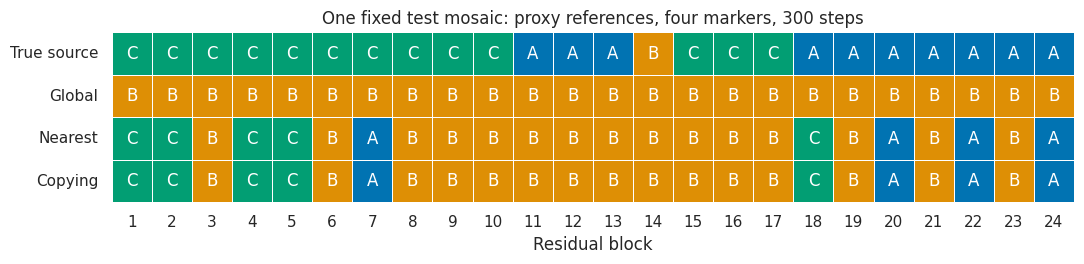

In [8]:
# fixed held-out example; no best-case selection
example = index.query("mosaic_id == 'test_long_000' and steps == 300 and variant == 'aligned' and panel == 'proxy' and markers == 4")
qid = int(example.query_id.iloc[0])
calls = [truth[qid]] + [pred['paths'][int(example.query('method == @method').prediction_id.iloc[0])] for method in method_order]
paint = pd.DataFrame(calls, index=['True source', 'Global', 'Nearest', 'Copying'], columns=np.arange(1, config['blocks'] + 1))
fig, ax = plt.subplots(figsize=(11, 2.8))
colors = sns.color_palette('colorblind', 3)
sns.heatmap(paint, cmap=colors, vmin=0, vmax=2, annot=np.array(['A', 'B', 'C'])[paint.to_numpy()], fmt='',
            cbar=False, linewidths=0.5, ax=ax)
ax.set(xlabel='Residual block', ylabel='', title='One fixed test mosaic: proxy references, four markers, 300 steps')
ax.tick_params(axis='y', rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT / 'ancestry_painting.png', dpi=180, bbox_inches='tight')
plt.show()

In [9]:
# compact headline tables; all conditions remain available in summary.csv
headline = summary.query("markers in [4, 600] and steps in [0, 300] and kind == 'long' and variant == 'aligned'")
headline.to_csv(OUTPUT / 'headline_results.csv', index=False)
display(headline[['panel', 'markers', 'steps', 'method', 'n', 'block_accuracy', 'boundary_f1', 'digit_accuracy']])
display(pd.read_csv(INPUT / 'open_set_metrics.csv').query('markers == 600 and steps == 300'))
display(summary.query("panel == 'exact' and markers == 600 and steps == 0 and kind == 'long' and method == 'copying'")[
    ['variant', 'n', 'block_accuracy', 'boundary_f1', 'digit_accuracy']])

,panel,markers,steps,method,n,block_accuracy,boundary_f1,digit_accuracy
60,exact,4,0,copying,24,1.000000,1.000000,0.973241
61,exact,4,0,global,24,0.545139,0.000000,0.973241
62,exact,4,0,nearest,24,1.000000,1.000000,0.973241
102,exact,4,300,copying,24,0.517361,0.318913,0.973241
103,exact,4,300,global,24,0.286458,0.000000,0.973241
104,exact,4,300,nearest,24,0.505208,0.340093,0.973241
240,exact,600,0,copying,24,1.000000,1.000000,0.973241
241,exact,600,0,global,24,0.559028,0.000000,0.973241
242,exact,600,0,nearest,24,1.000000,1.000000,0.973241
282,exact,600,300,copying,24,0.526042,0.408793,0.973241


,panel,markers,steps,unknown_auroc,unknown_average_precision,unknown_recall,known_false_rejection,unknown_blocks,known_blocks
19,exact,600,300,0.360159,0.087827,0.0,0.140420,102,762
39,proxy,600,300,0.338776,0.084475,0.0,0.049869,102,762


,variant,n,block_accuracy,boundary_f1,digit_accuracy
240,aligned,24,1.0000,1.000000,0.973241
243,oracle_restored,6,1.0000,1.000000,0.972963
246,permuted,6,0.3125,0.123148,0.972963


In [10]:
def markdown_table(frame):
    headings = '| ' + ' | '.join(frame.columns) + ' |'
    rule = '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |'
    rows = ['| ' + ' | '.join(map(str, row)) + ' |' for row in frame.itertuples(index=False, name=None)]
    return '\n'.join([headings, rule] + rows)

def comparison_table(markers):
    selected = summary.query("markers == @markers and kind == 'long' and variant == 'aligned'")
    table = selected.pivot(index=['panel', 'steps'], columns='method', values='block_accuracy').reset_index()
    for method in ['global', 'nearest', 'copying']:
        table[method] = table[method].map(lambda value: f'{100 * value:.2f}%')
    boundaries = selected.query("method == 'copying'")[['panel', 'steps', 'boundary_f1']]
    table = table.merge(boundaries, on=['panel', 'steps'])
    table['boundary_f1'] = table.boundary_f1.map(lambda value: f'{value:.3f}')
    return table.rename(columns={'panel': 'Panel', 'steps': 'Training steps', 'global': 'Global',
        'nearest': 'Nearest', 'copying': 'Copying', 'boundary_f1': 'Copying boundary F1'})

full_table, sparse_table = comparison_table(600), comparison_table(4)
sparse_gain = gains.query("panel == 'proxy' and markers == 4 and steps == 100 and kind == 'long'").iloc[0]
short_comparison = summary.query("panel == 'proxy' and markers == 4 and steps == 100 and kind == 'short' and variant == 'aligned'").set_index('method')
short_gain = gains.query("panel == 'proxy' and markers == 4 and steps == 100 and kind == 'short'").iloc[0]
permutation_table = summary.query("panel == 'exact' and markers == 600 and steps == 0 and kind == 'long' and method == 'copying'")[[
    'variant', 'n', 'block_accuracy', 'boundary_f1']].copy()
permutation_table['block_accuracy'] = permutation_table.block_accuracy.map(lambda value: f'{100 * value:.2f}%')
permutation_table['boundary_f1'] = permutation_table.boundary_f1.map(lambda value: f'{value:.3f}')
permutation_table.columns = ['Coordinates', 'Mosaics', 'Block accuracy', 'Boundary F1']
open_set = pd.read_csv(INPUT / 'open_set_metrics.csv').query('markers == 600 and steps in [0, 100, 300]')[[
    'panel', 'steps', 'unknown_auroc', 'unknown_recall', 'known_false_rejection']].copy()
for column in ['unknown_auroc', 'unknown_recall', 'known_false_rejection']:
    open_set[column] = open_set[column].map(lambda value: f'{value:.3f}')
open_set.columns = ['Panel', 'Training steps', 'Unknown AUROC', 'Unknown recall', 'Known false rejection']
checks = pd.read_csv(INPUT / 'gradient_checks.csv')
permutation_checks = pd.read_csv(INPUT / 'permutation_checks.csv')
digit_table = queries.query("split == 'test' and kind == 'long' and variant == 'aligned'").groupby('steps').digit_accuracy.mean()
gradient_max = checks.absolute_error.max()
permutation_max = permutation_checks.logit_max_error.max()
report = f'''# Results: local ancestry in block-spliced neural networks

This run used seed 63, a 24-block residual MLP, 18 calibration mosaics, and 56 test mosaics. Calibration and test donors were different branches. The main comparison below uses the 24 long-tract test mosaics: 576 block labels per setting. All percentages are measured on these constructed networks.

## What was implemented

- Trained one common ancestor, four source-family ancestors, eight donor checkpoints, and twelve reference siblings on digit classification. No ancestry tags were inserted into the weights.
- Constructed known source paths by copying actual residual-block tensors; saved further-training checkpoints at 0, 25, 100, and 300 Adam steps.
- Implemented a continuous-weight copying objective with a penalty for changing reference checkpoints, Viterbi decoding, and forward-backward posterior marginals. Proxy checkpoint marginals were aggregated to source lineages.
- Compared copying with independent nearest-reference matching and one-source global matching. Fit switch penalties and temperatures on calibration mosaics only.
- Tested sparse markers, short tracts, single-source controls, an absent source, and a function-preserving hidden-coordinate permutation.

## All 600 weights and biases per block

{markdown_table(full_table)}

Exact donor references recover all historical source labels and all boundaries through 100 further-training steps in this test. This success is also achieved by the nearest-reference baseline. Proxy panels recover source lineages rather than uniquely identify an unseen donor checkpoint.

After 300 steps, recovery degrades sharply even though mean digit test accuracy on long-tract mosaics is {100 * digit_table.loc[300]:.2f}% (versus {100 * digit_table.loc[0]:.2f}% before training). Thus a working classifier need not retain an easily recoverable donor history under this weight-distance method. These step counts describe this optimizer, learning rate, architecture, and training task; they are not general thresholds.

## Four markers per block

{markdown_table(sparse_table)}

At 100 training steps with proxy references and four markers per block, copying changes recovery by {100 * sparse_gain.mean_gain:.2f} percentage points relative to nearest matching. The paired whole-mosaic bootstrap 95% interval is [{100 * sparse_gain.ci_low:.2f}, {100 * sparse_gain.ci_high:.2f}] percentage points, conditional on this fixed source panel. All marker counts, checkpoints, and tract regimes are included in `f_evaluate/output/summary.csv`; this highlighted comparison is exploratory.

On short tracts at the same checkpoint, copying recovers {100 * short_comparison.loc['copying', 'block_accuracy']:.2f}% versus {100 * short_comparison.loc['nearest', 'block_accuracy']:.2f}% for nearest matching. The difference is {100 * short_gain.mean_gain:.2f} percentage points, with fixed-panel bootstrap interval [{100 * short_gain.ci_low:.2f}, {100 * short_gain.ci_high:.2f}]. A continuity prior can therefore erase real rapid source changes; improvement on long tracts is not a general improvement across splice patterns.

The useful role of continuity in this pilot is to pool weak local evidence when only a few coordinates are observed. It does not establish an advantage over full-weight nearest matching in the easy conditions, or a remedy for extensive training drift.

## Coordinate permutation

{markdown_table(permutation_table)}

The permuted and oracle-restored rows use the same six fixed mosaics. The aligned row summarizes all 24 long-tract mosaics; their aligned recovery is perfect before training. The largest observed logit change under the permutation was {permutation_max:.2e}; applying the known inverse restored every tensor exactly. Raw-coordinate inference therefore fails on some functionally identical parameterizations. No automatic permutation alignment is implemented.

## Missing source

{markdown_table(open_set)}

The fourth source was absent from the inference panel. Rejection used a fixed calibration residual threshold, independently of the forced A/B/C calls. It works best before substantial drift and deteriorates with further training. In particular, high source-assignment confidence must not be interpreted as evidence that all true sources are present in the reference panel.

## Checks and scope

- Maximum finite-difference gradient discrepancy: {gradient_max:.2e} across the six parameter groups checked.
- Viterbi and forward-backward matched exhaustive enumeration on a four-block, three-state case; duplicate-reference posterior aggregation was checked separately.
- Every initial splice was verified against its recorded donor tensors. Permutation reversibility and one-to-one boundary matching were checked.
- The delivered pipeline contains code-only notebooks, seed 63, a traceable symlink chain, trained weights, truth, predictions, calibration settings, and plots.

The supported result is that ancestry continuity can improve sparse-coordinate reconstruction in aligned, shared-ancestor networks, while direct weight matching already solves many well-observed cases. This pilot does not establish robust recovery after extensive training, invariance to equivalent parameterizations, unique donor identification from proxy relatives, or performance on LLMs. Repeating the study over independent source panels is needed before treating the effect sizes as population-level results.

The method adapts the copying formulation used in [Loter](https://doi.org/10.1093/molbev/msy126). [modelDNA](https://arxiv.org/abs/2607.10617) is relevant prior work on model provenance and merge decomposition; this pilot does not establish novelty relative to that literature. See `METHODS.md` for the exact objective and scoring definitions.
'''
(OUTPUT / 'RESULTS.md').write_text(report)
(TASK.parent / 'RESULTS.md').write_text(report)
display(pd.DataFrame({'report': ['RESULTS.md'], 'long_tract_test_mosaics': [24],
    'sparse_proxy_gain_percentage_points': [100 * sparse_gain.mean_gain]}))


,report,long_tract_test_mosaics,sparse_proxy_gain_percentage_points
0,RESULTS.md,24,10.590278
